In [1]:
import pandas as pd
data = pd.read_csv("Wholesale customers data.csv")
data

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


In [2]:
data = data[['Fresh','Milk']]

In [5]:
from sklearn.preprocessing import Normalizer
scaler = Normalizer()
fitted_data = scaler.fit_transform(data)

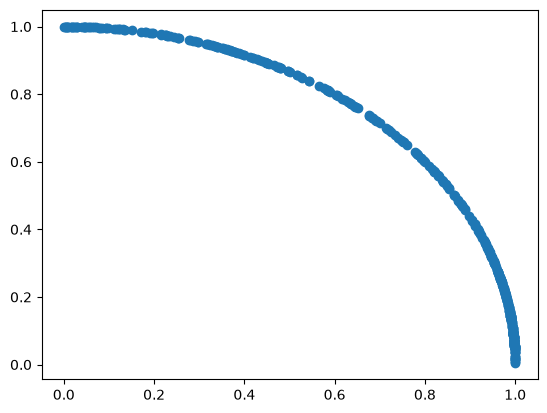

In [14]:
plt.scatter(fitted_data[:,0], fitted_data[:,1])
plt.show()

In [6]:
fitted_data

array([[0.79532795, 0.60617939],
       [0.58396679, 0.81177755],
       [0.58498615, 0.81104328],
       [0.99596001, 0.08979783],
       [0.9725588 , 0.23265722],
       [0.75168063, 0.65952728],
       [0.96691839, 0.25508592],
       [0.83694432, 0.54728804],
       [0.85303067, 0.52186079],
       [0.47611714, 0.87938187],
       [0.52876989, 0.84876522],
       [0.99636468, 0.08519047],
       [0.93214581, 0.36208313],
       [0.95976001, 0.28082152],
       [0.93356015, 0.35842075],
       [0.99414922, 0.10801543],
       [0.11493204, 0.99337336],
       [0.69040588, 0.72342223],
       [0.94673148, 0.32202409],
       [0.95223211, 0.30537521],
       [0.9683974 , 0.24941228],
       [0.98798071, 0.15457719],
       [0.99812686, 0.06117819],
       [0.58647661, 0.80996616],
       [0.91811231, 0.39632031],
       [0.96742633, 0.2531527 ],
       [0.9953198 , 0.09663592],
       [0.99842181, 0.05615948],
       [0.19686164, 0.98043128],
       [0.99881444, 0.04867969],
       [0.

EPS: 0.01, Number of clusters: 20
EPS: 0.012222222222222221, Number of clusters: 18
EPS: 0.014444444444444444, Number of clusters: 17
EPS: 0.016666666666666666, Number of clusters: 15
EPS: 0.018888888888888886, Number of clusters: 12
EPS: 0.02111111111111111, Number of clusters: 8
EPS: 0.02333333333333333, Number of clusters: 5
EPS: 0.025555555555555554, Number of clusters: 4
EPS: 0.027777777777777776, Number of clusters: 3
EPS: 0.03, Number of clusters: 2


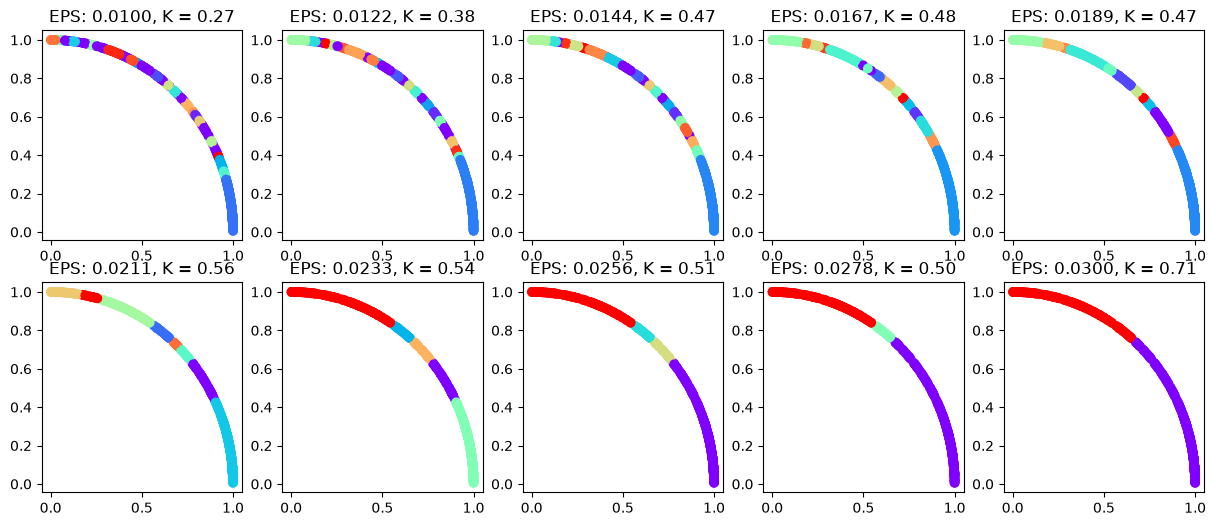

In [35]:
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
ins_num = 10
list_eps = np.linspace(0.01, 0.03, ins_num)
fig, ax = plt.subplots(2, ins_num//2, figsize=(15, 6))
for idx in range(len(list_eps)):
    cluster = DBSCAN(eps=list_eps[idx], min_samples=5)
    labels = cluster.fit_predict(fitted_data)
    print(f"EPS: {list_eps[idx]}, Number of clusters: {len(set(labels)) - (1 if -1 in labels else 0)}")
    ax[idx//(ins_num//2), idx%(ins_num//2)].scatter(fitted_data[:, 0], fitted_data[:, 1], c=labels, cmap='rainbow')
    silhouette = silhouette_score(fitted_data, labels) if len(set(labels)) > 1 else -1
    if silhouette != -1:
        silhouette = f"{silhouette:.2f}"
    ax[idx//(ins_num//2), idx%(ins_num//2)].set_title(f"EPS: {list_eps[idx]:.4f}, K = {silhouette}")
plt.show()


In [40]:
best_eps =  0.027777777777777776
print(f"Best EPS: {best_eps}")
cluster = DBSCAN(eps=best_eps, min_samples=5)
labels = cluster.fit_predict(fitted_data)
cluster.labels_

Best EPS: 0.027777777777777776


array([0, 1, 1, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 1, 2, 0, 0, 2, 0, 0, 0, 0, 2,
       0, 2, 2, 1, 0, 2, 0, 1, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0, 0, 1, 0, 2,
       2, 0, 2, 0, 0, 0, 1, 0, 0, 0, 2, 0, 0, 2, 0, 2, 0, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 2, 0, 2, 2, 2, 0, 0, 0, 0, 2, 2, 0, 0, 0, 2, 1, 2, 2,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2,
       0, 2, 1, 0, 2, 2, 2, 0, 0, 2, 1, 0, 1, 0, 0, 0, 2, 2, 2, 2, 2, 2,
       0, 0, 0, 2, 0, 0, 2, 1, 2, 0, 0, 2, 0, 2, 0, 0, 0, 2, 0, 0, 0, 2,
       0, 0, 2, 2, 0, 1, 0, 2, 0, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 0, 2, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 2, 0, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       2, 2, 2, 0, 0, 0, 0, 2, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0,

In [41]:
# Number of noise points
noise_points = np.sum(labels == -1)
print(f"Number of noise points: {noise_points}")

Number of noise points: 0


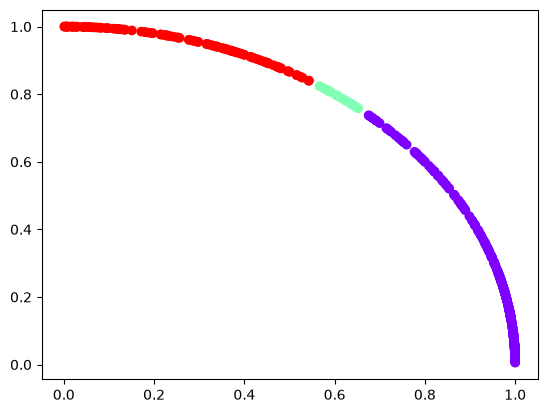

In [42]:
plt.scatter(fitted_data[:,0], fitted_data[:,1], c=labels, cmap='rainbow')